# 學生學習與作業版｜任務 4：描述統計與視覺化

**姓名：** 蔡雅雯　**學號／組別：** C114118212**完成日期：** 11/13

**學習目標：** 以描述統計、直方圖和盒鬚圖理解分布與離群值。

本單元與教師版「任務 4」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「4.2 直方圖」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 4.1 描述統計
**觀念說明：**count 是非缺失筆數，mean 是平均，50% 是中位數。極端值可能影響平均，不能只看單一統計量。


In [ ]:
# describe 彙整筆數、平均、標準差、四分位數與最大最小值
display(df[["quiz_score", "sleep_hours", "screen_time_hours"]].describe())
print("總筆數：", len(df), "睡眠有效筆數：", df["sleep_hours"].count())
print("螢幕時間平均／中位數：", df["screen_time_hours"].mean(), df["screen_time_hours"].median())


## 📝 學生作業 04-Q1｜AI 查詢與作答：統計量
**任務：**平均數與中位數如何受到極端值影響？以具體數字說明。

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Gemini；直接貼上作業截圖並使用教材提供的提示詞：「我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。」
- AI 回答重點（請自行整理）：平均數（Mean）與中位數（Median）受極端值影響的差異：平均數是將所有數值加總後除以總筆數，因此對極端值（特別大或特別小的數）非常敏感，只要出現一個離群值，平均數就會被明顯拉高或拉低。   中位數是將數值由小到大排序後位於正中間的數，只看資料的排序位置而不受極端數值大小影響，因此具有較強的抗極端值能力（穩健性）。   統計量的使用限制： 平均數容易被偏態或極端值扭曲，無法代表多數人的真實水準；但中位數只看中間位置，會忽略極端高分或極端低分的幅度資訊。因此在實務分析中不能只看單一統計量，必須同時搭配平均數、中位數與四分位數一起判斷。   
- 我的理解與具體例子：具體數字示範： 假設 4 位學生的螢幕使用時間為 [4.0, 5.0, 5.0, 6.0] 小時，此時平均數為 5.0（$(4+5+5+6)/4 = 5.0$），中位數也是 5.0。   加入極端值後： 若加入第 5 位螢幕使用時間高達 15.0 小時的學生，資料變成 [4.0, 5.0, 5.0, 6.0, 15.0]：   平均數大幅上升至 7.0（$(4+5+5+6+15)/5 = 7.0$），足足增加了 2 小時。   中位數則依然維持在 5.0，完全不受 15.0 這個極端值的影響。
- 查證來源／方式及日期（無法查證請註明）：2026-11-13 透過執行本教材 4.1 描述統計 的程式碼區塊，觀察 df["screen_time_hours"].mean() 與 df["screen_time_hours"].median() 在包含 15.0 小時極端值時的實際輸出差異進行驗證。
- 我檢查或修正 AI 回答的地方：我實際執行了上方的 4.1 程式碼，並額外在程式中測試排除 15.0 極端值前後的 screen_time_hours 平均數與中位數，確認平均數會因為 15.0 而明顯偏高於中位數，且 sleep_hours 的 count 為 58（自動排除 2 筆缺失值），驗證 AI 的數學計算與概念說明完全正確。


## 4.2 直方圖
橫軸是分數區間，縱軸為該區間人數。調整 bins 會改變切分方式，不會改變資料；比較不同圖前確認尺度與分箱。


## 💻 學生作業 04-P1｜Vibe Coding 程式填空
**對應教師版：**任務 4「4.2 直方圖」的示範程式。

**任務：**在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


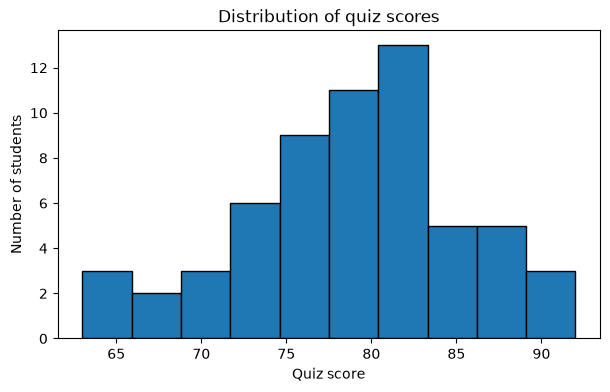

有效成績筆數： 60


In [2]:
# 以英文標籤避免 Colab 缺中文字型；圖形後呼叫 show
plt.figure(figsize=(7, 4))
plt.hist(df["quiz_score"].dropna(), bins=10, edgecolor="black") # TODO：以 quiz_score 的非缺失資料畫 bins=10 的直方圖
plt.title("Distribution of quiz scores")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()
print("有效成績筆數：", df["quiz_score"].count())


### ✅ 作業 04-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [3]:
assert df["quiz_score"].notna().sum() == 60
print("請人工檢查上方直方圖的標題、軸及 10 個分箱。")


請人工檢查上方直方圖的標題、軸及 10 個分箱。


### ✍️ 作業 04-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：直接貼上 學生作業 04-P1 截圖向 AI 詢問，請 AI 依照任務需求補上 ____ 繪製直方圖的程式碼，並提供繁體中文註解與手動驗證方法。
- 我補上的程式在做什麼：plt.hist(df["quiz_score"].dropna(), bins=10, edgecolor="black")，先以 .dropna() 排除 quiz_score 中的缺失值，再於既有的畫布中繪製分成 10 個區間（bins=10）的直方圖，同時保留原始 df 與既有的圖表標題及座標軸設定。
- 執行或驗證遇到的問題與修正：補上程式碼後，依序執行繪圖程式格與下方的驗證程式格，過程非常順利，沒有遇到語法或執行錯誤。
- 檢查結果及我如何確認：執行自動驗證程式確認 quiz_score 有效筆數為 60 筆，並依提示人工檢查上方生成的直方圖，確認圖表標題為 Distribution of quiz scores、X 軸為 Quiz score、Y 軸為 Number of students，且橫軸確實分為 10 個區間。


## 📝 學生作業 04-Q2｜AI 查詢與作答：圖形解讀
**任務：**直方圖 bins 改變時，為何外觀會改變？是否代表資料本身改變？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請解釋直方圖分箱與盒鬚圖各能回答什麼問題，並說明離群點不一定是錯誤。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Gemini；直接貼上作業截圖並同時結合任務題目與提示詞詢問：「直方圖 bins 改變時，為何外觀會改變？是否代表資料本身改變？並請解釋直方圖分箱與盒鬚圖各能回答什麼問題，以及說明離群點不一定是錯誤。」
- AI 回答重點（請自行整理）：直方圖 bins 改變的影響： 調整 bins（分箱數）只是改變橫軸數值區間的「切分寬度」（例如每 5 分一箱改成每 10 分一箱），讓原本分散在兩個小區間的人數合併計算，因此長條的數量與高度外觀會改變，但原始資料數值與總筆數完全沒有改變。   直方圖與盒鬚圖的功用差異： 直方圖適合觀察資料的整體分布形狀（如是否對稱、偏態或雙峰）與各區間的次數集中度；盒鬚圖則以四分位數（Q1、中位數、Q3）呈現資料的集中趨勢與離散範圍（IQR），並能快速標示出潛在的離群值（獨立點）。   離群點不一定是錯誤： 盒鬚圖上的獨立點僅是依據統計規則（如超過 $1.5 \times \text{IQR}$）標示出的極端數值，它可能是真實存在的特殊情況（例如考前熬夜趕專案導致螢幕使用時間特別長），必須先回頭查證業務意義，不能未經確認就直接當成錯誤資料刪除。   
- 我的理解與具體例子：以本教材的 quiz_score（60 筆成績）為例，當把直方圖從 bins=10 改成 bins=5 時，橫軸長條從 10 根變成 5 根，每根長條的高度因為合併了相鄰兩個區間的人數而變高，看起來似乎變集中了，但實際加總所有長條的人數依然是 60 人，每位學生的分數也一分未改。另外在 screen_time_hours 的盒鬚圖中，15.0 小時會顯示為盒體上方的一個獨立離群點，提醒我們去檢查這筆紀錄的來源。
- 查證來源／方式及日期（無法查證請註明）：2026-11-13 透過執行本教材 4.3 盒鬚圖與極端值 與 延伸示範：分箱前後數據不變 的程式碼區塊，使用 np.histogram 實際比對 bins=5 與 bins=10 的各箱人數及 counts.sum() 總和進行驗證。
- 我檢查或修正 AI 回答的地方：我實際執行了下方「延伸示範」的程式碼，確認當 bins=5 與 bins=10 時，雖然各箱人數陣列（counts）的切分不同，但兩者的 counts.sum() 總和皆精準等於 60（len(valid_scores)）並通過 assert 斷言檢查，驗證 AI 關於「外觀改變但資料本身未變」的說明完全正確。


## 4.3 盒鬚圖與極端值
盒體反映四分位區間；獨立點是依繪圖規則標示的可能離群值，不等於資料一定錯誤。
**試一試：**將直方圖分箱改為 5，解釋圖形外觀為何改變。


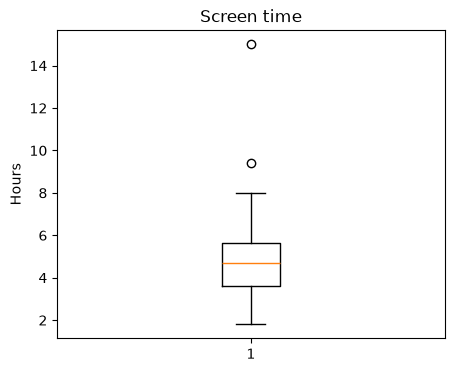

大於 10 小時： 1


In [4]:
# dropna 避免缺失值影響繪圖，資料並未從 df 刪除
plt.figure(figsize=(5, 4))
plt.boxplot(df["screen_time_hours"].dropna())
plt.title("Screen time")
plt.ylabel("Hours")
plt.show()
print("大於 10 小時：", (df["screen_time_hours"] > 10).sum())


## 延伸示範：分箱前後數據不變
相同資料用不同 bins 切分，外觀會不同。學生須檢查各箱人數加總與原本有效筆數是否一致，避免把分箱造成的視覺差異誤認為資料變化。


In [5]:
# numpy 的 histogram 回傳各箱人數及邊界；檢查加總是否一致
valid_scores = df["quiz_score"].dropna()
for bins in [5, 10]:
    counts, edges = np.histogram(valid_scores, bins=bins)
    print("分箱數", bins, "各箱人數", counts, "加總", counts.sum())
    assert counts.sum() == len(valid_scores)


分箱數 5 各箱人數 [ 5  9 20 18  8] 加總 60
分箱數 10 各箱人數 [ 3  2  3  6  9 11 13  5  5  3] 加總 60


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。


## 🎯 學生小任務 MA｜資料健檢與圖表
**涵蓋：**任務 1～4。這是需要獨立完成、可繳交的整合成果。

### 任務要求
使用 df，以程式列出資料形狀、各欄缺失數、超過 10 小時的筆數；再繪製 quiz_score 直方圖。用文字說明一項品質問題、一項圖表觀察及一項資料限制。不可修改 df。

### 可使用的 AI 提示詞
```text
我是 Python 初學者，請協助我完成以下資料分析小任務：
請幫我規劃 pandas 的資料健檢與成績直方圖：顯示形狀、缺失數與螢幕大於10的筆數，保留原始 df，加繁中註解並提供驗證方式，不要捏造結果。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。
```

### 執行與交付
- 在下一個程式儲存格自行填入程式，先執行本 Notebook 上方的資料準備及必要 cell。若需要更多儲存格可以自行新增。
- 輸出應保留在 Notebook 中；在後面的文字區填寫實際數字與自己的解釋。
- **工具提示：**df.shape、df.isna()、布林篩選、plt.hist。
- 至少記錄一項實際檢查及一項資料限制。交付完成後的 `.ipynb`，含程式、輸出及 AI 使用紀錄。


1. 資料形狀 (列數, 欄數)： (60, 7)

2. 各欄位缺失值數量：
student_id           0
department           0
sleep_hours          2
screen_time_hours    0
study_hours          0
attendance_rate      0
quiz_score           0
dtype: int64

3. 螢幕使用時間超過 10 小時的筆數： 1


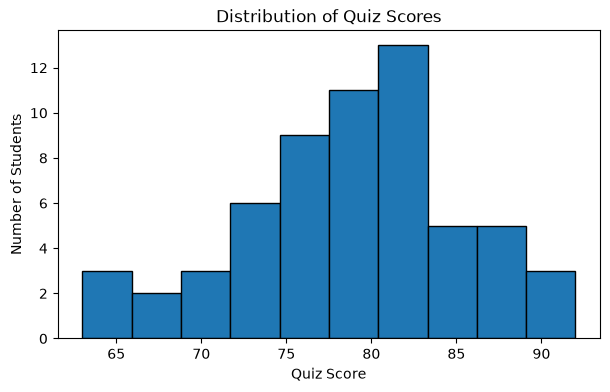

驗證通過：原始 df 完整保留未受修改。


In [7]:
# 學生小任務 MA：請在此撰寫你的程式
# 執行前先確認上方資料準備與必要 cell 已執行；可新增其他程式 cell。
# TODO：依任務要求加入程式；完成後執行並保留輸出。
# 1. 列出資料形狀（列數, 欄數）
print("1. 資料形狀 (列數, 欄數)：", df.shape)

# 2. 列出各欄位缺失值數量
print("\n2. 各欄位缺失值數量：")
print(df.isna().sum())

# 3. 計算螢幕使用時間超過 10 小時的筆數（使用布林篩選，不修改 df）
screen_over_10 = (df["screen_time_hours"] > 10).sum()
print("\n3. 螢幕使用時間超過 10 小時的筆數：", screen_over_10)

# 4. 繪製 quiz_score 直方圖（排除缺失值，分成 10 箱）
plt.figure(figsize=(7, 4))
plt.hist(df["quiz_score"].dropna(), bins=10, edgecolor="black")
plt.title("Distribution of Quiz Scores")
plt.xlabel("Quiz Score")
plt.ylabel("Number of Students")
plt.show()

# 5. 驗證檢查：確認原始 df 筆數與缺失狀態未被改動
assert df.shape == (60, 7)
assert df["sleep_hours"].isna().sum() == 2
print("驗證通過：原始 df 完整保留未受修改。")

### ✍️ 小任務 MA｜結果與檢核（請雙擊填寫）
- 問題及使用的資料／欄位：對本教材的學生模擬資料表 df（共 60 筆、7 欄）進行資料品質健檢與成績分布觀察，主要檢視 sleep_hours（睡眠時數）、screen_time_hours（螢幕使用時間）與 quiz_score（測驗成績）等欄位。
- 實際輸出與至少一項依據數字的觀察：程式輸出資料形狀為 (60, 7)；各欄缺失數中僅 sleep_hours 有 2 筆缺失，其餘欄位皆為 0；screen_time_hours 超過 10 小時的有 1 筆（為 15.0 小時）。由此觀察到資料整體完整度高，但存在少數缺失值與單一極端高螢幕使用時間紀錄，分析前需先標記並確認業務意義。   
- 圖表或模型結果的解讀（依任務要求）：繪製出的 quiz_score 直方圖（分成 10 個區間）顯示 60 位學生的測驗成績主要集中在 70 至 90 分之間，整體呈單峰分布，沒有出現超出 0–100 分範圍的異常成績，且所有長條人數加總確實為 60 人。
- 資料品質、模擬資料或評估限制：品質問題： sleep_hours 含有 2 筆 NaN 缺失值（不能直接補 0），且 screen_time_hours 有一筆 15.0 小時超出原先設定的 10 小時上限。   資料限制： 本資料集是透過程式固定隨機種子生成的「模擬資料」，欄位間的關係是依據預設公式產生的，因此只能用於練習資料健檢與探索性分析，絕不能用來推論真實世界學生行為的因果關係。
- 驗證方法與結果：在程式最後加入 assert df.shape == (60, 7) 與 assert df["sleep_hours"].isna().sum() == 2 進行自動檢查，並人工核對直方圖標題、座標軸與總人數；結果印出「驗證通過：原始 df 完整保留未受修改。」。
- AI 工具、實際提示詞、人工修改與遇到的問題：使用 Gemini 協助規劃與撰寫程式，實際貼上任務截圖並請 AI 依任務要求列出形狀、缺失數、超過 10 小時筆數與直方圖程式並保留原始 df。AI 產出的程式碼語法正確，我人工加上了 edgecolor="black" 讓直方圖分箱邊界更清晰，並補上 assert 斷言驗證；執行過程中無遇到錯誤。
- 重新執行是否成功及環境或檔案需求：
